# Model Kaybı ve Doğruluğunu Grafikle Takip Etme
Bu örnekte:
- Modelin doğruluk ve kayıp değerlerini izleme
- Aşırı öğrenmeyi engellemek için Dropout kullanma
- EarlyStopping ile eğitim sürecini otomatik durdurma
- MNIST veri setiyle görsel sınıflandırma yapılacaktır.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping


## MNIST Verisini Yükleme ve Hazırlama

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(-1, 28*28) / 255.0
x_test = x_test.reshape(-1, 28*28) / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Dropout ve EarlyStopping Kullanılan Model

In [3]:
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(784,)))
model.add(Dropout(0.3))  # %30 nöron devre dışı
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Model Eğitimi ve Takibi

In [4]:
history = model.fit(x_train, y_train,
                    epochs=20,
                    batch_size=128,
                    validation_data=(x_test, y_test),
                    callbacks=[early_stop],
                    verbose=1)


Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7873 - loss: 0.7116 - val_accuracy: 0.9524 - val_loss: 0.1611
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9429 - loss: 0.1945 - val_accuracy: 0.9634 - val_loss: 0.1169
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9551 - loss: 0.1469 - val_accuracy: 0.9692 - val_loss: 0.0976
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9628 - loss: 0.1226 - val_accuracy: 0.9729 - val_loss: 0.0878
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9677 - loss: 0.1043 - val_accuracy: 0.9753 - val_loss: 0.0797
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9704 - loss: 0.0952 - val_accuracy: 0.9764 - val_loss: 0.0768
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9736 - loss: 0.0826 - val_accuracy: 0.9753 - val_loss: 0.0773
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9751 - loss: 0.0772 - val_accuracy: 0

## Doğruluk ve Kayıp Grafikleri

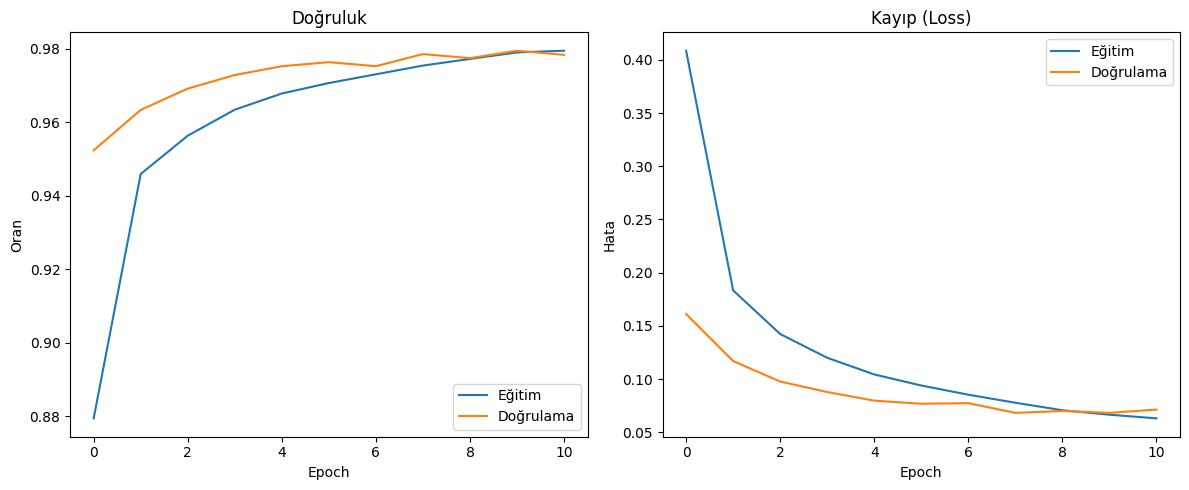

In [5]:
plt.figure(figsize=(12,5))

# Doğruluk grafiği
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim')
plt.plot(history.history['val_accuracy'], label='Doğrulama')
plt.title("Doğruluk")
plt.xlabel("Epoch")
plt.ylabel("Oran")
plt.legend()

# Kayıp grafiği
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim')
plt.plot(history.history['val_loss'], label='Doğrulama')
plt.title("Kayıp (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Hata")
plt.legend()

plt.tight_layout()
plt.show()


## Örnek Görsel Tahmini

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step


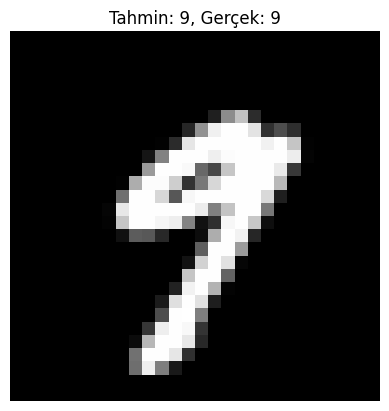

In [6]:
index = 20
sample = x_test[index].reshape(1, -1)
prediction = model.predict(sample)

plt.imshow(x_test[index].reshape(28,28), cmap='gray')
plt.title(f"Tahmin: {np.argmax(prediction)}, Gerçek: {np.argmax(y_test[index])}")
plt.axis('off')
plt.show()
